In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

In [ ]:
data=pd.read_csv("/content/drive/MyDrive/Wine prediction model/wine_quality_merged.csv")

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [ ]:
data.head(6)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,red


In [ ]:
data.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'type'],
      dtype='object')

In [ ]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import seaborn as sns

In [ ]:
data.shape

(6497, 13)

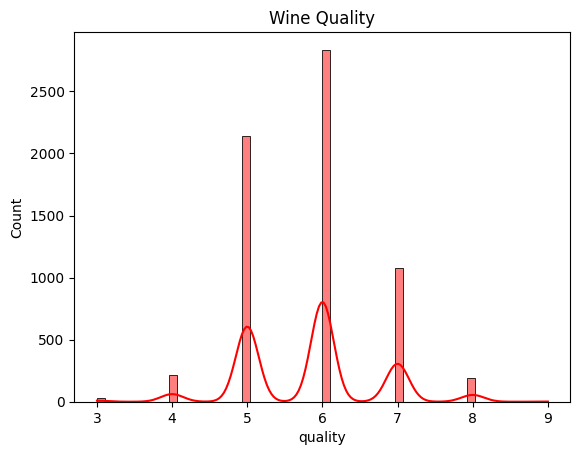

In [ ]:
sns.histplot(data['quality'],kde=True,color="red")
plt.title("Wine Quality")
plt.show()

<Axes: xlabel='count', ylabel='type'>

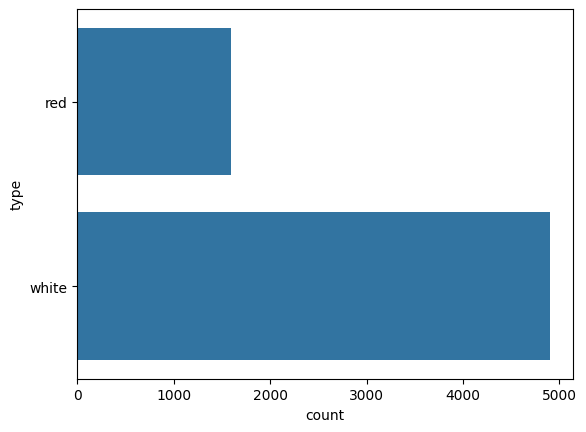

In [ ]:
sns.countplot(data['type'])

<Axes: ylabel='fixed acidity'>

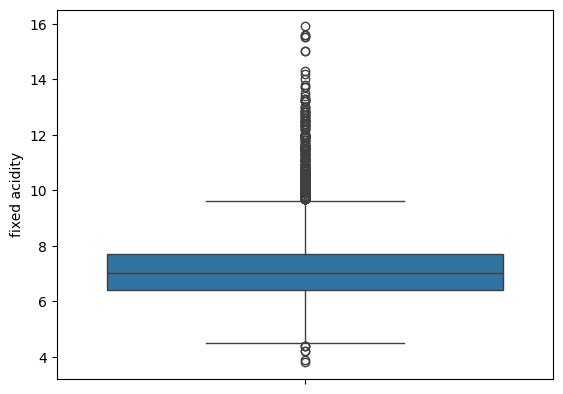

In [ ]:
sns.boxplot(data["fixed acidity"])

In [ ]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
data["type"]=le.fit_transform(data["type"])

In [ ]:
data.skew(numeric_only= True)

,0
fixed acidity,1.723290
volatile acidity,1.495097
citric acid,0.471731
residual sugar,1.435404
chlorides,5.399828
free sulfur dioxide,1.220066
total sulfur dioxide,-0.001177
density,0.503602
pH,0.386839
sulphates,1.797270


In [ ]:
x= data.drop("type",axis=1)
y=data["type"]

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt= DecisionTreeClassifier()
dt.fit(x_train,y_train)

y_pred_dtc= dt.predict(x_test)


In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix


In [ ]:
print("accuracy ", accuracy_score(y_test,y_pred_dtc))

accuracy  0.9846153846153847


In [ ]:
print("accuracy ", accuracy_score(y_test,y_pred_dtc))

accuracy  0.9846153846153847


In [ ]:
cm= confusion_matrix(y_test,y_pred_dtc)

<Axes: >

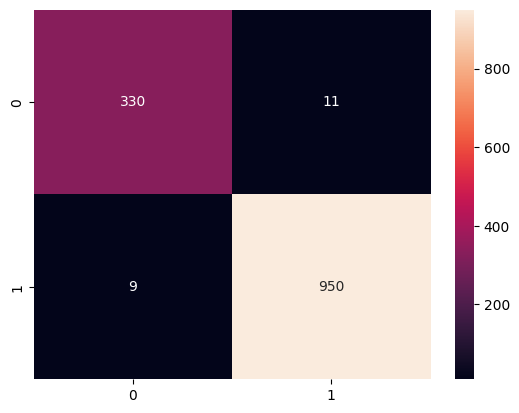

In [ ]:
sns.heatmap(cm,annot=True,fmt="d")

In [ ]:
print(cm)

[[330  11]
 [  9 950]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf= RandomForestClassifier()
rf.fit(x_train,y_train)

y_pred_rfc= rf.predict(x_test)

In [ ]:
print("accuracy ", accuracy_score(y_test,y_pred_rfc))


accuracy  0.9953846153846154


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
gb= GradientBoostingClassifier()
gb.fit(x_train,y_train)

y_pred_gbc= gb.predict(x_test)

In [ ]:
print("accuracy ", accuracy_score(y_test,y_pred_rfc))


accuracy  0.9953846153846154


In [ ]:
importances=dt.feature_importances_
features = x.columns

In [ ]:
fea_imp= pd.DataFrame({"Feature":features,"Importance":importances})

In [ ]:
fea_imp.head()

,Feature,Importance
0,fixed acidity,0.004687
1,volatile acidity,0.049486
2,citric acid,0.001336
3,residual sugar,0.003285
4,chlorides,0.206613


In [ ]:
fea_imp=fea_imp.sort_values(by="Importance",ascending=False)

In [ ]:
fea_imp.head(5)

,Feature,Importance
6,total sulfur dioxide,0.690122
4,chlorides,0.206613
1,volatile acidity,0.049486
9,sulphates,0.014181
7,density,0.013508


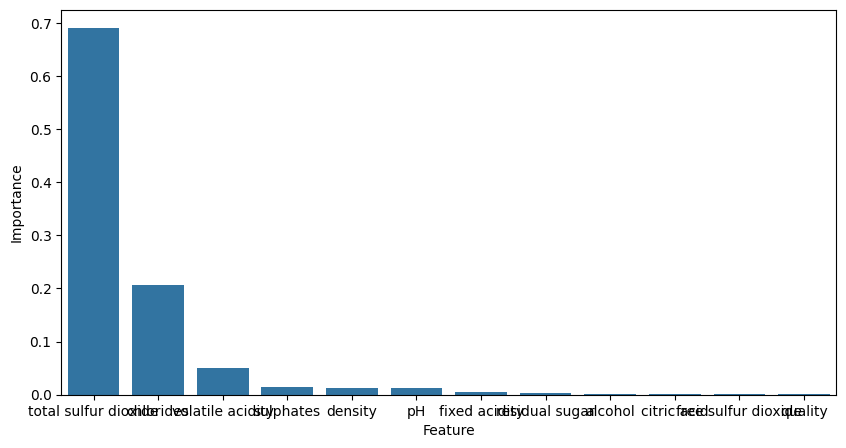

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(data=fea_imp,x="Feature",y="Importance")
plt.show()

In [ ]:
import joblib

In [ ]:
joblib.dump(dt,"Wine_type_dt.pkl")

['Wine_type_dt.pkl']

In [ ]:
from google.colab import files
files.download("Wine_type_dt.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>